# Ejercicio 3. Verificación de una pila con mínimo

Este cuaderno acompaña al informe [`ejercicio-03.md`](ejercicio-03.md). Ejecuta la misma clase, comprueba el invariante contra una pila de referencia, cuenta comparaciones y genera `ejercicio-03.png`. Las secciones siguen la numeración del informe.

Se usa una representación enlazada con nodos de tres campos de tamaño fijo. En el modelo del informe, comparar valores y reservar o liberar uno de esos nodos cuesta tiempo constante. Para reproducir el cuaderno hacen falta Python 3 y `matplotlib`.

In [1]:
from itertools import product

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

## 1. Formulación

La pila acepta valores de un orden total, incluidos repetidos. `pop`, `peek` y `minimum` lanzan `IndexError` en vacío. El oráculo usa una lista, `pop` y `min`; su costo no forma parte del costo de la implementación.

## 2. Diseño y algoritmo

Cada nodo es `(value, prefix_minimum, next_node)`. El siguiente campo referencia otro nodo, sin copiarlo. La clase que sigue es idéntica a la del informe.

In [2]:
class MinStack:
    __slots__ = ("_top",)

    def __init__(self):
        self._top = None

    def is_empty(self):
        return self._top is None

    def push(self, x):
        previous = self._top
        if previous is None or x < previous[1]:
            cached_min = x
        else:
            cached_min = previous[1]
        self._top = (x, cached_min, previous)

    def pop(self):
        node = self._top
        if node is None:
            raise IndexError("desapilar de una pila vacía")
        self._top = node[2]
        return node[0]

    def peek(self):
        if self._top is None:
            raise IndexError("tope de una pila vacía")
        return self._top[0]

    def minimum(self):
        if self._top is None:
            raise IndexError("mínimo de una pila vacía")
        return self._top[1]

In [3]:
def nodes_from_bottom(stack):
    nodes = []
    current = stack._top
    while current is not None:
        nodes.append((current[0], current[1]))
        current = current[2]
    return list(reversed(nodes))


example_stack = MinStack()
example_operations = ['inicio']
example_minimums = [float('nan')]
for x in [5, 3, 3, 7]:
    example_stack.push(x)
    example_operations.append(f'+{x}')
    example_minimums.append(example_stack.minimum())

example_nodes = nodes_from_bottom(example_stack)
assert example_nodes == [(5, 5), (3, 3), (3, 3), (7, 3)]
print('posición   valor   mínimo guardado')
for i, (value, minimum) in enumerate(example_nodes, 1):
    print(f'{i:8} {value:7} {minimum:17}')

outputs, minimums_after_pop = [], []
while not example_stack.is_empty():
    value = example_stack.pop()
    minimum = None if example_stack.is_empty() else example_stack.minimum()
    outputs.append(value)
    minimums_after_pop.append(minimum)
    example_operations.append(f'−{value}')
    example_minimums.append(float('nan') if minimum is None else minimum)
    print(f'pop -> {value}; mínimo restante: {minimum}')

assert outputs == [7, 3, 3, 5]
assert minimums_after_pop == [3, 3, 5, None]

posición   valor   mínimo guardado
       1       5                 5
       2       3                 3
       3       3                 3
       4       7                 3
pop -> 7; mínimo restante: 3
pop -> 3; mínimo restante: 3
pop -> 3; mínimo restante: 5
pop -> 5; mínimo restante: None


## 3. Invariante y correctitud

El monitor comprueba que la cadena tiene exactamente los valores de la pila de referencia, en orden inverso, y que cada nodo guarda el mínimo del prefijo correspondiente. También comprueba `is_empty`, `peek` y `minimum`, incluidas las excepciones en vacío. Las consultas deben conservar la identidad de la cima.

Estas inspecciones son código de pruebas y pueden recorrer toda la pila. Los métodos de `MinStack` no contienen recorridos.

In [4]:
def expect_index_error(operation):
    try:
        operation()
    except IndexError:
        return
    raise AssertionError('La operación debía lanzar IndexError')


def validate_stack(stack, reference):
    root = stack._top
    current = root
    for i in range(len(reference) - 1, -1, -1):
        assert isinstance(current, tuple) and len(current) == 3
        assert current[0] == reference[i]
        assert current[1] == min(reference[:i + 1])
        current = current[2]
    assert current is None
    assert stack.is_empty() == (len(reference) == 0)
    if reference:
        assert stack.peek() == reference[-1]
        assert stack.minimum() == min(reference)
    else:
        expect_index_error(stack.peek)
        expect_index_error(stack.minimum)
    assert stack._top is root, 'Una consulta modificó la cima'


p = MinStack()
validate_stack(p, [])
expect_index_error(p.pop)
validate_stack(p, [])
for x in [5, 3, 3, 7]:
    p.push(x)
validate_stack(p, [5, 3, 3, 7])
print('ok: pila vacía, excepciones y estado del ejemplo')

ok: pila vacía, excepciones y estado del ejemplo


## 4. Costo y espacio

Se instrumenta la comparación `<` con valores que cuentan cuántas veces se comparan. Para cada inserción se verifica que hay cero comparaciones si la pila estaba vacía y exactamente una en caso contrario. Además, el nuevo nodo debe enlazar con la antigua cima. Las consultas y las extracciones no deben comparar valores.

Se usan órdenes creciente, decreciente, constante y alternado. Esta cuenta comprueba las comparaciones; la garantía de tiempo constante se demuestra en el informe contando también los accesos, la reserva de un nodo fijo y los cambios de referencias. No se infiere a partir de mediciones de reloj.

In [5]:
class Key:
    comparisons = 0

    def __init__(self, value):
        self.value = value

    def __lt__(self, other):
        Key.comparisons += 1
        return self.value < other.value


sizes = [0, 1, 2, 8, 64, 512, 4096]
patterns = {
    'creciente': lambda n: list(range(n)),
    'decreciente': lambda n: list(range(n, 0, -1)),
    'constante': lambda n: [3] * n,
    'alternado': lambda n: [i if i % 2 == 0 else -i for i in range(n)],
}
cost_cases = 0
cost_pushes = 0
for name, generate in patterns.items():
    for n in sizes:
        stack, reference = MinStack(), []
        Key.comparisons = 0
        for value in generate(n):
            previous = stack._top
            before = Key.comparisons
            stack.push(Key(value))
            reference.append(value)
            assert Key.comparisons - before == int(previous is not None)
            assert stack._top[2] is previous
            assert len(stack._top) == 3
            before = Key.comparisons
            assert not stack.is_empty()
            assert stack.peek().value == reference[-1]
            assert stack.minimum().value == min(reference)
            assert Key.comparisons == before
            cost_pushes += 1
        while reference:
            before = Key.comparisons
            next_node = stack._top[2]
            assert stack.pop().value == reference.pop()
            assert stack._top is next_node
            if reference:
                assert stack.peek().value == reference[-1]
                assert stack.minimum().value == min(reference)
            assert Key.comparisons == before
        before = Key.comparisons
        assert stack.is_empty()
        expect_index_error(stack.pop)
        expect_index_error(stack.peek)
        expect_index_error(stack.minimum)
        assert Key.comparisons == before
        assert Key.comparisons == max(0, n - 1)
        cost_cases += 1

assert cost_cases == 28
print(f'ok: {cost_cases} casos de costo; {cost_pushes:,} inserciones y extracciones')
print('push en vacío: 0 comparaciones; push no vacía: 1 comparación')
print('pop, peek, minimum e is_empty: 0 comparaciones entre valores')
print('ok: cada nodo nuevo enlaza con la cima anterior; cada extracción avanza un nodo')

ok: 28 casos de costo; 18,732 inserciones y extracciones
push en vacío: 0 comparaciones; push no vacía: 1 comparación
pop, peek, minimum e is_empty: 0 comparaciones entre valores
ok: cada nodo nuevo enlaza con la cima anterior; cada extracción avanza un nodo


## 5. Casos de prueba

Se enumeran todas las secuencias de longitudes 0 a 6 sobre cuatro modificaciones: `push(-1)`, `push(0)`, `push(1)` y `pop()`. Se permite desapilar en vacío para comprobar las excepciones y la conservación del estado. Antes de la primera modificación y después de cada una se ejecuta el monitor completo, incluidas todas las consultas.

In [6]:
actions = [('push', -1), ('push', 0), ('push', 1), ('pop', None)]
sequences = modifications = states = 0
for length in range(7):
    for sequence in product(actions, repeat=length):
        stack, reference = MinStack(), []
        validate_stack(stack, reference)
        states += 1
        for operation, value in sequence:
            if operation == 'push':
                stack.push(value)
                reference.append(value)
            elif reference:
                assert stack.pop() == reference.pop()
            else:
                previous = stack._top
                expect_index_error(stack.pop)
                assert stack._top is previous
            modifications += 1
            validate_stack(stack, reference)
            states += 1
        sequences += 1

assert sequences == sum(4**k for k in range(7)) == 5_461
assert modifications == sum(k * 4**k for k in range(7))
assert states == sequences + modifications
print(f'ok: {sequences:,} secuencias exhaustivas')
print(f'ok: {modifications:,} modificaciones y {states:,} estados inspeccionados')
print('ok: orden de la pila, mínimo de cada nodo, consultas y excepciones')

ok: 5,461 secuencias exhaustivas
ok: 30,948 modificaciones y 36,409 estados inspeccionados
ok: orden de la pila, mínimo de cada nodo, consultas y excepciones


## Figura 1

La figura muestra los cuatro nodos del ejemplo y el mínimo después de cada modificación. Las flechas apuntan desde cada nodo hacia el que tenía debajo al insertarse. En vacío, el mínimo no está definido y la operación lanza `IndexError`.

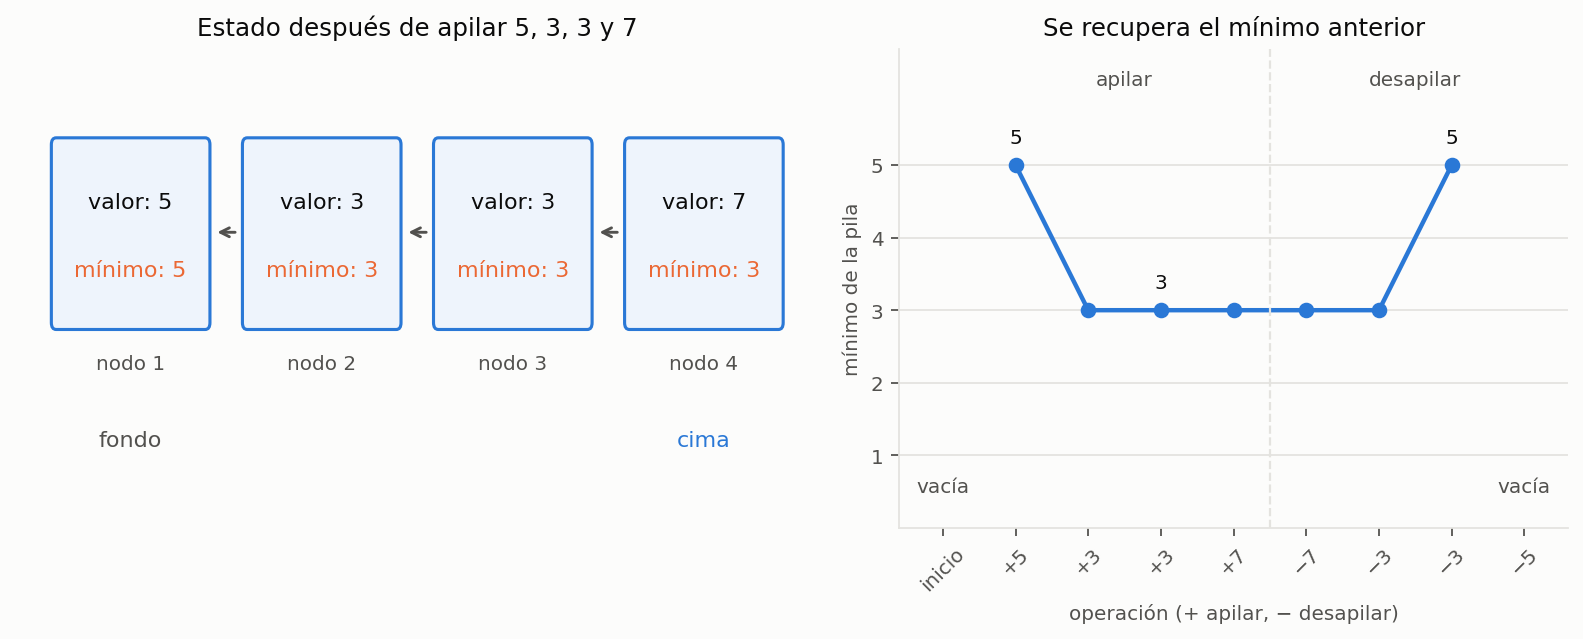

In [7]:
blue, orange = '#2a78d6', '#eb6834'
ink, secondary_ink, grid_color, background = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
fig, (ax_n, ax_m) = plt.subplots(1, 2, figsize=(10, 4.1), dpi=160,
                                 gridspec_kw={'width_ratios': [1.2, 1]})
fig.patch.set_facecolor(background)
ax_n.set_facecolor(background)
for i, (value, minimum) in enumerate(example_nodes):
    box = FancyBboxPatch((i - 0.39, 0.05), 0.78, 0.65,
                         boxstyle='round,pad=0.025', linewidth=1.4,
                         edgecolor=blue, facecolor='#eef4fc')
    ax_n.add_patch(box)
    ax_n.text(i, 0.47, f'valor: {value}', ha='center', color=ink, fontsize=10)
    ax_n.text(i, 0.22, f'mínimo: {minimum}', ha='center', color=orange, fontsize=10)
    ax_n.text(i, -0.12, f'nodo {i + 1}', ha='center', color=secondary_ink, fontsize=9)
    if i:
        ax_n.annotate('', xy=(i - 1 + 0.43, 0.38), xytext=(i - 0.43, 0.38),
                      arrowprops=dict(arrowstyle='->', color=secondary_ink, lw=1.3))
ax_n.text(0, -0.4, 'fondo', ha='center', color=secondary_ink, fontsize=10)
ax_n.text(3, -0.4, 'cima', ha='center', color=blue, fontsize=10)
ax_n.set_xlim(-0.6, 3.6)
ax_n.set_ylim(-0.7, 1.05)
ax_n.set_title('Estado después de apilar 5, 3, 3 y 7', fontsize=11, color=ink)
ax_n.axis('off')

ax_m.set_facecolor(background)
ax_m.plot(range(9), example_minimums, 'o-', color=blue, lw=2, ms=6)
for i in [0, 8]:
    ax_m.text(i, 0.5, 'vacía', ha='center', color=secondary_ink, fontsize=9)
for i in [1, 3, 7]:
    ax_m.annotate(str(int(example_minimums[i])), (i, example_minimums[i]),
                  xytext=(0, 10), textcoords='offset points', ha='center',
                  color=ink, fontsize=9)
ax_m.axvline(4.5, color=grid_color, lw=1, ls='--')
ax_m.text(2.5, 6.1, 'apilar', ha='center', color=secondary_ink, fontsize=9)
ax_m.text(6.5, 6.1, 'desapilar', ha='center', color=secondary_ink, fontsize=9)
ax_m.set_xticks(range(9), example_operations, rotation=45)
ax_m.set_yticks([1, 2, 3, 4, 5])
ax_m.set_ylim(0, 6.6)
ax_m.set_xlim(-0.6, 8.6)
ax_m.set_xlabel('operación (+ apilar, − desapilar)', fontsize=9, color=secondary_ink)
ax_m.set_ylabel('mínimo de la pila', fontsize=9, color=secondary_ink)
ax_m.set_title('Se recupera el mínimo anterior', fontsize=11, color=ink)
ax_m.grid(axis='y', color=grid_color, lw=0.8)
for side in ['top', 'right']:
    ax_m.spines[side].set_visible(False)
for side in ['left', 'bottom']:
    ax_m.spines[side].set_color(grid_color)
ax_m.tick_params(colors=secondary_ink, labelsize=9)
fig.tight_layout()
fig.savefig('ejercicio-03.png', facecolor=background)
plt.show()

## 6. Conclusiones

El mínimo de cada nodo resume el contenido desde ese nodo hasta el fondo. Apilar agrega un resumen correcto y desapilar recupera uno ya calculado. El invariante de todos los nodos permite demostrar ambas operaciones y el tratamiento de repetidos.

Cada operación realiza trabajo constante en el peor caso bajo el modelo del informe. La información de mínimos ocupa una palabra adicional por nodo. Las pruebas verifican los casos enumerados; la demostración cubre cualquier secuencia de operaciones.

In [8]:
print('Todas las comprobaciones finalizaron correctamente.')
print(f'Secuencias exhaustivas: {sequences:,}')
print(f'Casos de costo: {cost_cases}; tamaño máximo: {max(sizes)}')
print('Figura guardada en ejercicio-03.png')

Todas las comprobaciones finalizaron correctamente.
Secuencias exhaustivas: 5,461
Casos de costo: 28; tamaño máximo: 4096
Figura guardada en ejercicio-03.png
